In [ ]:
import torch
from torch import optim
from torch import nn
from torch.utils.data import Dataset, DataLoader, random_split
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
!mkdir /content/models

In [ ]:

# 1개의 특성(X)과 1개의 타깃(y)을 가진 분류 데이터셋 생성
X, y = make_classification(
    n_samples=1000,           # 데이터 샘플 개수
    n_features=1,            # 전체 특성(X) 개수
    n_informative=1,         # 예측에 유용한 특성 개수
    n_redundant=0,           # 다른 특성으로부터 유도 가능한 쓸모없는 특성 개수
    n_repeated=0,            # 중복 특성 개수
    n_classes=2,             # 분류할 클래스 개수 (이진 분류)
    n_clusters_per_class=1,  # 클래스당 클러스터 개수
    random_state=42          # 재현성을 위한 난수 고정
)

x = X.squeeze()

# 데이터 크기 및 샘플 확인
print("X 크기:", x.shape)
print("y 크기:", y.shape)
print("\nX 상위 5개:\n", X[:5])
print("\ny 상위 5개:\n", y[:5])  # numpy.ndarray

# x * 표준편차 + 평균
x = x*15 + 50
print(x[:5])

df = pd.DataFrame({'x' : x,
      'y' : y})

X 크기: (1000,)
y 크기: (1000,)

X 상위 5개:
 [[-1.86929547]
 [-0.70735509]
 [-1.64877149]
 [-1.30731491]
 [-0.83443017]]

y 상위 5개:
 [0 0 0 0 0]
[21.960568   39.38967369 25.2684276  30.39027638 37.48354747]


In [ ]:
class MyDataset1(Dataset):
  def __init__(self, df):
    self.df = df
    self.x = self.df.iloc[:,0].values
    self.y = self.df.iloc[:,1].values
    self.length = len(self.df)

  def __getitem__(self, index):
    x = torch.FloatTensor([self.x[index]])
    y = torch.FloatTensor([self.y[index]])
    return x, y

  def __len__(self):
    return self.length

class MyModel1(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer = nn.Sequential(
        nn.Linear(1,1),
        nn.Sigmoid()
    )

  def forward(self, x):
    x = self.layer(x)
    return x

epoch: 10, loss: 0.32
epoch: 20, loss: 0.23
epoch: 30, loss: 0.19
epoch: 40, loss: 0.25
epoch: 50, loss: 0.14
epoch: 60, loss: 0.12
epoch: 70, loss: 0.14
epoch: 80, loss: 0.12
epoch: 90, loss: 0.16
epoch: 100, loss: 0.11
epoch: 110, loss: 0.12
epoch: 120, loss: 0.08
epoch: 130, loss: 0.06
epoch: 140, loss: 0.06
epoch: 150, loss: 0.07
epoch: 160, loss: 0.05
epoch: 170, loss: 0.07
epoch: 180, loss: 0.07
epoch: 190, loss: 0.05
epoch: 200, loss: 0.07
Training Complete
평가점수: 0.03


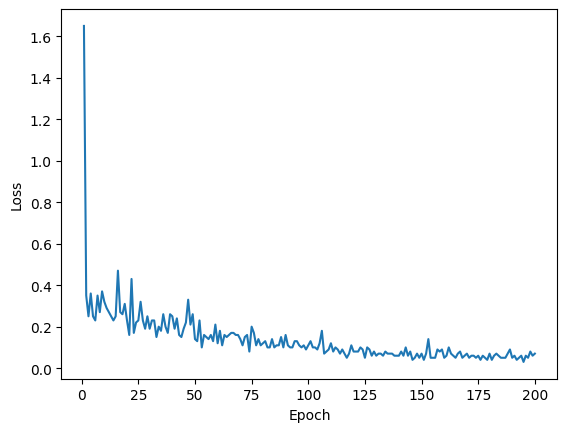

In [ ]:
# Trainer
device = 'cuda' if torch.cuda.is_available() else 'cpu'
dataset = MyDataset1(df)
train_size = 800
eval_size = 200
batch_size = 10
train_dataset, eval_dataset = random_split(dataset, [train_size, eval_size])
train_dataloader = DataLoader(train_dataset, batch_size = batch_size,
                                 shuffle = True,
                                 drop_last = True)
eval_dataloader = DataLoader(eval_dataset, batch_size = batch_size,
                             shuffle = True,
                             drop_last = True)

learning_rate = 0.01
epoch = 200

model = MyModel1().to(device)
criterion = nn.BCELoss().to(device)
optimizer = optim.SGD(model.parameters(), lr = learning_rate)


epoch_memory = [x+1 for x in range(200)]
loss_memory = []
checkpoint = 0

for epoch in range(epoch):
  cost = torch.FloatTensor([0.0])
  for x, y in train_dataloader:
    x = x.to(device)
    y = y.to(device)
    output = model(x)

    loss = criterion(output, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    cost += loss

  loss_memory.append(round(cost.item() / len(train_dataset), 2))
  checkpoint += 1

  if (epoch+1) % 10 == 0:
      print(f"epoch: {epoch+1}, loss: {(cost.item() / len(train_dataset)):.2f}")

  if (epoch+1) % 100 == 0:
    torch.save({"model" : "MyModel",
                "epoch" : epoch,
              "model_state_dict":model.state_dict(),
              "optimizer_state_dict":optimizer.state_dict(),
              "cost":cost,
              "description":f"MyModel Checkpoint {checkpoint}"
              }, f"models/checkpoint-{checkpoint}.pt")

plt.plot(epoch_memory, loss_memory)
plt.xlabel('Epoch')
plt.ylabel('Loss')

torch.save(model, "models/model.pt")
torch.save(model.state_dict(), "models/model_state_dict.pt")
print('Training Complete')

# evaluation
model = torch.load('models/model.pt', map_location = device, weights_only = False)
model.eval()

with torch.no_grad():
  cost = torch.FloatTensor([0.0])
  for x, y in eval_dataloader:
    x = x.to(device)
    y = y.to(device)
    output = model(x)
    loss = criterion(output, y)
    cost += loss.item()


model = torch.load('models/model.pt', map_location = device, weights_only = False)
cost = round(cost.item() / len(eval_dataset), 2)
print('평가점수:', cost)

# inference
def model_infer(x):
  model = torch.load('models/model.pt', map_location = device, weights_only = False)
  model.eval()

  output = round(model(torch.FloatTensor([x]).to(device)).item())
  if output >= 100 :
    output = 100

  return output